In [1]:
import warnings; warnings.filterwarnings('ignore')
import pandas as pd
import holidays
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
from prophet import Prophet
from xgboost import XGBRegressor


Importing plotly failed. Interactive plots will not work.


In [2]:
df = pd.read_csv('dados/station_data_dataverse.csv')
df.columns = df.columns.str.lower()
df = df.drop_duplicates()

In [3]:
df['created'] =pd.to_datetime(df['created'], errors='coerce')
df = df.dropna(subset=['created', 'kwhtotal'])
df= df[df['kwhtotal'] > 0]
df.shape

(3340, 24)

In [4]:
serie = df.set_index('created')['kwhtotal'].resample('D').sum()
serie = serie.asfreq('D', fill_value=0)
serie.shape

(321,)

In [5]:
print(serie.index.min(), serie.index.max())
print((serie == 0).sum(), 'dias sem sessão')

dias_zero = serie[serie == 0]
print(dias_zero.index.dayofweek.value_counts().sort_index())

0014-11-18 00:00:00 0015-10-04 00:00:00
84 dias sem sessão
created
0     8
1     5
2     4
3     6
4     9
5    20
6    32
Name: count, dtype: int64


In [6]:
feriados = holidays.US()

dados = pd.DataFrame({'y': serie})
dados['dia_semana'] = dados.index.dayofweek
dados['mes'] = dados.index.month
dados['feriado'] = [int(d in feriados) for d in dados.index]
dados.head()

,y,dia_semana,mes,feriado
created,,,,
14-11-18,13.39,1,11,0
14-11-19,18.77,2,11,0
14-11-20,6.95,3,11,0
14-11-21,14.14,4,11,0
14-11-22,0.00,5,11,0


In [7]:
corte = int(len(dados) * 0.8)
treino, teste = dados.iloc[:corte], dados.iloc[corte:]
len(treino), len(teste)

(256, 65)

In [8]:
def avaliar(real, previsto):
    mae = mean_absolute_error(real, previsto)
    rmse = np.sqrt(mean_squared_error(real, previsto))
    return round(mae, 2), round(rmse, 2)

resultados, previsoes = {}, {}

previsoes['baseline'] = np.full(len(teste), treino['y'].mean())
resultados['baseline'] = avaliar(teste['y'], previsoes['baseline'])

In [9]:
melhor_aic= None
for ordem in [(1, 1, 1), (2, 1, 2), (7, 1, 1)]:
    ajuste = ARIMA(treino['y'], order=ordem).fit()
    if melhor_aic is None or ajuste.aic < melhor_aic:
        melhor_aic, melhor_ordem, arima_modelo = ajuste.aic, ordem, ajuste
print('ordem escolhida:', melhor_ordem)

previsoes['ARIMA'] = arima_modelo.forecast(steps=len(teste)).values
resultados['ARIMA'] = avaliar(teste['y'], previsoes['ARIMA'])

c:\Users\natnu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\natnu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
c:\Users\natnu\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params


ordem escolhida: (7, 1, 1)


In [10]:
df_p = treino.reset_index().rename(columns={'created': 'ds'})[['ds', 'y']]

prophet_modelo = Prophet(weekly_seasonality=True, daily_seasonality=False, yearly_seasonality=False)
prophet_modelo.add_country_holidays(country_name='US')
prophet_modelo.fit(df_p)

futuro = pd.DataFrame({'ds': teste.index})
previsoes['Prophet'] = prophet_modelo.predict(futuro)['yhat'].values
resultados['Prophet'] = avaliar(teste['y'], previsoes['Prophet'])

11:13:08 - cmdstanpy - INFO - Chain [1] start processing
11:13:09 - cmdstanpy - INFO - Chain [1] done processing


In [11]:
colunas_x = ['dia_semana', 'mes', 'feriado']

xgb_modelo = XGBRegressor(n_estiamtors=200, max_depth=3, learning_rate=0.1, random_state=42)
xgb_modelo.fit(treino[colunas_x], treino['y'])

previsoes['XGBoost'] = xgb_modelo.predict(teste[colunas_x])
resultados['XGBoost'] = avaliar(teste['y'], previsoes['XGBoost'])


             MAE    RMSE
XGBoost    38.06   49.91
ARIMA      51.13   57.83
Prophet    58.88   65.16
baseline  111.59  128.30
melhor: XGBoost


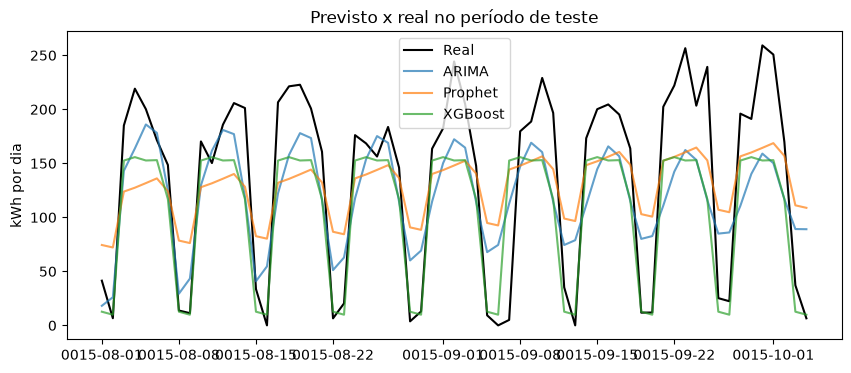

In [13]:
tabela = pd.DataFrame(resultados, index=['MAE', 'RMSE']).T.sort_values('RMSE')
print(tabela)
melhor = tabela.index[0]
print('melhor:', melhor)

plt.figure(figsize=(10, 4))
plt.plot(teste.index, teste['y'], label='Real', color='black')
for nome in ['ARIMA', 'Prophet', 'XGBoost']:
    plt.plot(teste.index, previsoes[nome], label=nome, alpha=0.7)
plt.ylabel('kWh por dia')
plt.title('Previsto x real no período de teste')
plt.legend()
plt.show()